<a href="https://colab.research.google.com/github/Shahad-Hossain/nasa-image-enhancement/blob/main/Homework_4_%26_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from PIL import Image
import math
from collections import defaultdict
import random
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
input1 = "MarsSample4.jpg"
try:
    img1 = Image.open(input1).convert('L') # Convert to RGB to ensure consistent 3-channel access
except FileNotFoundError:
    print(f"Error: The file '{input1}' was not found.")
    exit()

pixels1 = img1.load()

width1, height1 = img1.size

print(str(width1) + " " + str(height1))

img1.save("grayscaled.jpg")

800 583


In [ ]:
#Gaussian - additive noise

mean = 184
sigma = 67

def gaussian(z):
  partOne = 1 / (math.sqrt(2 * math.pi) * sigma)

  exponent = -1 * (math.pow(z - mean, 2)) / (2 * math.pow(sigma, 2))

  return partOne * math.exp(exponent)

cdf = []
sum = 0
for i in range(256):
  gauDen = gaussian(i)

  sum += gauDen

  cdf.append(sum)

def gaussian_random():
  rng = random.random()

  for i in range(256):
    if rng <= cdf[i]:
      return i

  return -1


#Salt and Pepper - impulse noise

pepper = 0
pepperProb = 0.05
salt = 255
saltProb = 0.05

def sp_random():
  rng = random.random()

  stayProbability = 1 - pepperProb - saltProb
  if (rng < stayProbability):
    return 1;
  elif (rng < stayProbability + pepperProb):
    return pepper
  else:
    return salt;


#Uniform - additive noise

val1 = 52
val2 = 194

probability = 1 / (val2 - val1)
cdf1 = []
sum = 0
for i in range(val1, val2):
  sum += probability
  cdf1.append(sum)

def uniform_random():
  rng = random.random()
  for i in range(len(cdf1)):
    if rng <= cdf1[i]:
      return i + val1


#Exponential - additive noise

a = 0.01

def exponential(z):
  return a * math.exp(-1 * a * z)


sum = 0
for i in range(0, 256):
  sum += exponential(i)

normalizeConstant = sum

def exponential(z):
  return a * math.exp(-1 * a * z) / normalizeConstant

cdf2 = []
sum = 0
for i in range(256):
  expDen = exponential(i)

  sum += expDen

  cdf2.append(sum)

def exponential_random():
  rng = random.random()

  for i in range(256):
    if rng <= cdf2[i]:
      return i

  return -1


#Rayleigh - additive noise
a1 = 25
b1 = 500

def rayleigh(z):
  z = z / 8
  exponent = -1 * (math.pow(z - a1, 2) / b1)

  return (2 / b1) * (z - a1) * math.exp(exponent)


normalizeConstantRay = 0
for i in range(256):
  normalizeConstantRay += rayleigh(i)

def rayleigh(z):
  z = z / 8
  exponent = -1 * (math.pow(z - a1, 2) / b1)

  return (2 / b1) * (z - a1) * math.exp(exponent) / normalizeConstantRay

cdf3 = []
sum = 0
for i in range(256):
  sum += rayleigh(i)

  cdf3.append(sum)

def rayleigh_random():
  rng = random.random()

  for i in range(256):
    if rng <= cdf3[i]:
      return i

  return -1

In [ ]:
#Gaussian Noise Generator

noiseImg = Image.new(mode="L", size=(width1, height1))

noisePixels = noiseImg.load()
for i in range(width1):
  for j in range(height1):
    noisePixels[i, j] = gaussian_random()


noiseImg.save("noise.jpg")

In [ ]:
#Salt and Pepper Noise Generator

noiseImg = Image.new(mode="L", size=(width1, height1))

noisePixels = noiseImg.load()
for i in range(width1):
  for j in range(height1):
    noisePixels[i, j] = sp_random()



noiseImg.save("noise.jpg")

In [ ]:
#Uniform Noise Generator

noiseImg = Image.new(mode="L", size=(width1, height1))

noisePixels = noiseImg.load()
for i in range(width1):
  for j in range(height1):
    noisePixels[i, j] = uniform_random()


noiseImg.save("noise.jpg")

In [ ]:
#Exponential Noise Generator

noiseImg = Image.new(mode="L", size=(width1, height1))

noisePixels = noiseImg.load()
for i in range(width1):
  for j in range(height1):
    noisePixels[i, j] = exponential_random()


noiseImg.save("noise.jpg")

In [ ]:
#Rayleigh Noise Generator

noiseImg = Image.new(mode="L", size=(width1, height1))

noisePixels = noiseImg.load()
for i in range(width1):
  for j in range(height1):
    noisePixels[i, j] = rayleigh_random()


noiseImg.save("noise.jpg")

In [ ]:
#Logarithmic Addition (assuming greyscaled)

M = 255

outImg = Image.new(mode="L", size=(width1, height1))

outPixels = outImg.load()
for i in range(width1):
  for j in range(height1):
    pixelVal1 = pixels1[i, j]
    pixelVal2 = noisePixels[i, j]

    newPixelVal = int(pixelVal1 + pixelVal2 - ((pixelVal1 * pixelVal2) / M))

    outPixels[i, j] = 255 - newPixelVal

outImg.save("output.jpg")

In [ ]:
#Invert image aka g(i, j) for logarithmic image processing

for i in range(width1):
  for j in range(height1):
    pixelVal1 = pixels1[i, j]
    pixelVal2 = noisePixels[i, j]

    pixels1[i, j] = 255 - pixelVal1
    noisePixels[i, j] = 255 - pixelVal2

In [ ]:
#Add
max_add = -1
outImg = Image.new(mode="L", size=(width1, height1))

outPixels = outImg.load()
for i in range(width1):
  for j in range(height1):
    pixelVal1 = pixels1[i, j]
    pixelVal2 = noisePixels[i, j]

    newPixelVal = pixelVal1 + pixelVal2

    if (newPixelVal > max_add):
      max_add = newPixelVal

    outPixels[i, j] = newPixelVal

outImg.save("output.jpg")

In [ ]:
#Normalized Addition
outImg = Image.new(mode="L", size=(width1, height1))

outPixels = outImg.load()
for i in range(width1):
  for j in range(height1):
    pixelVal1 = pixels1[i, j]
    pixelVal2 = noisePixels[i, j]

    newPixelVal = int(((pixelVal1 + pixelVal2) / max_add) * 255)

    outPixels[i, j] = newPixelVal

outImg.save("output.jpg")

In [ ]:
#Multiply
outImg = Image.new(mode="L", size=(width1, height1))

outPixels = outImg.load()
for i in range(width1):
  for j in range(height1):
    pixelVal1 = pixels1[i, j]
    pixelVal2 = noisePixels[i, j]

    newPixelVal = pixelVal1 * pixelVal2

    outPixels[i, j] = min(255, newPixelVal)

outImg.save("output.jpg")

In [ ]:
#Mean Squared Error
outImg = Image.open("output.jpg")

outPixels = outImg.load()

sum10 = 0
for i in range(width1):
  for j in range(height1):
    noisyImgPixel = outPixels[i, j]
    referenceImgPixel = pixels1[i, j]

    sum10 += math.pow(noisyImgPixel - referenceImgPixel, 2)

sum10 /= (width1 * height1)

print(sum10)

17.415575


In [ ]:
#EMEE
alpha1 = 1
def filterFunction(neighborhood):
  maxNum = max(neighborhood)
  minNum = min(neighborhood)

  return alpha1 * math.pow(maxNum / (minNum + 1), alpha1) * math.log(maxNum / (minNum + 1))

blockWidth = 3
blockHeight = 3

k1 = width1 // blockWidth
k2 = height1 // blockHeight

count = 0
sum = 0

for i in range(k1):
  for j in range(k2):
    neighborhood = []
    count += 1
    for k in range(i * blockWidth, (i + 1) * blockWidth):
      for l in range(j * blockHeight, (j + 1) * blockHeight):
        if (k < width1 and l < height1):
          neighborhood.append(outPixels[k, l])

    sum += filterFunction(neighborhood)

sum /= (k1 * k2)

print(sum)

0.07424702059276633


### **Estimating noise parameters**

In [ ]:
#Zoom into segment of image
startx = 20
endx =  90
starty = 10
endy = 100
zoomImg = Image.new(mode="L", size=(endx - startx, endy - starty))

zoomPixels = zoomImg.load()

outPixels = img1.load()
for i in range(startx, endx):
  for j in range(starty, endy):
    pixelVal1 = outPixels[i, j]

    zoomPixels[i - startx, j - starty] = pixelVal1

zoomImg.save("zoom.jpg")

In [ ]:
histogram = defaultdict(int)
size = 0
zoomMean = 0
zoomVariance = 0

for i in range(endx - startx):
  for j in range(endy - starty):
    histogram[zoomPixels[i, j]] += 1

histogramArray = []
for i in range(256):
  histogramArray.append(histogram[i])

for i in range(256):
  zoomMean += i * histogramArray[i]
  size += histogramArray[i]

zoomMean /= size

for i in range(256):
  zoomVariance += math.pow(i - zoomMean, 2) * (histogramArray[i] / size)

print(str(zoomMean) + " " + str(zoomVariance))

115.34947368421052 281.3873418282549


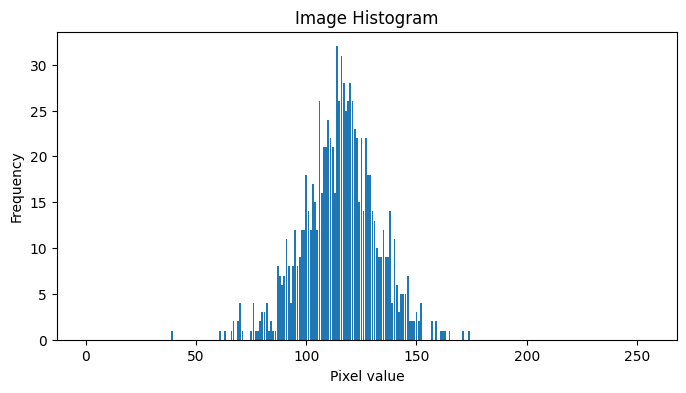

0


In [ ]:
# ---- zoom histogram ----
histogram = defaultdict(int)

for i in range(endx - startx):
  for j in range(endy - starty):
    histogram[zoomPixels[i, j]] += 1

histogramArray = []

for i in range(256):
  histogramArray.append(histogram[i])
# ---- plot histogram as bars ----
plt.figure(figsize=(8,4))
plt.bar(range(256), histogramArray)
plt.title("Image Histogram")
plt.xlabel("Pixel value")
plt.ylabel("Frequency")
plt.show()
print(histogramArray[1])

In [ ]:
#Uniform noise curve estimation

min_range_est = 256
max_range_est = -1

zoomPixels = Image.open("zoom.jpg").load()
for i in range(endx - startx):
  for j in range(endy - starty):
    min_range_est = zoomPixels[i,j] if zoomPixels[i,j] < max_range_est else max_range_est
    max_range_est = zoomPixels[i,j] if zoomPixels[i,j] > max_range_est else max_range_est

print(str(min_range_est) + " " + str(max_range_est))

57 93


In [ ]:
#Salt and pepper noise curve estimation

count = 0

for i in range(endx - startx):
  for j in range(endy - starty):
    if (zoomPixels[i, j] == 0 or zoomPixels[i, j] == 255):
      count += 1

probability = count / ((endx - startx) * (endy - starty))
print(probability)

0.0529


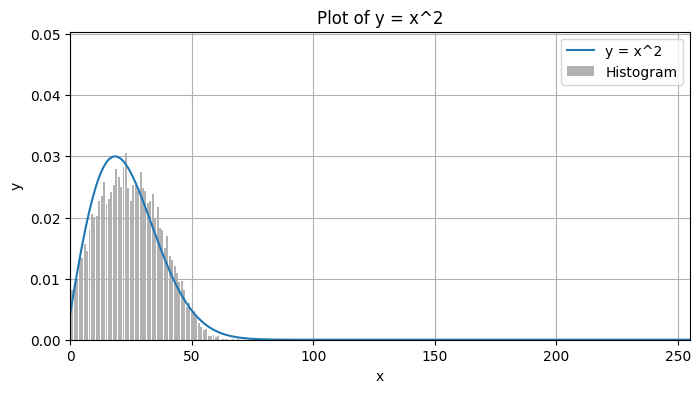

In [ ]:
#Rayleigh noise curve estimation

graphb = (4 * zoomVariance) / (4 - math.pi)
grapha = zoomMean - (math.sqrt((math.pi * graphb) / 4))

def rayleighGraph(z):
  exponent = -1 * (np.power(z - grapha, 2) / graphb)

  return (2 / graphb) * (z - grapha) * np.exp(exponent)

normalizedHistogramArray = []

max = -1
for i in range(256):
  normalizedHistogramArray.append(histogramArray[i] / size)
  if (normalizedHistogramArray[i] > max):
    max = normalizedHistogramArray[i]

# Define the range of x values
x = np.linspace(0, 256, 400)  # 400 points between -10 and 10

# Define the function
y = rayleighGraph(x)

plt.figure(figsize=(8,4))
plt.bar(range(256), normalizedHistogramArray, color='gray', alpha=0.6, label='Histogram')


# Plot the function
plt.plot(x, y, label='y = x^2')

# Add labels and title
plt.xlabel('x')
plt.xlim(0, 255)
plt.ylim(0, max + 0.01)
plt.ylabel('y')
plt.title('Plot of y = x^2')
plt.legend()
plt.grid(True)

# Show the plot
plt.show()

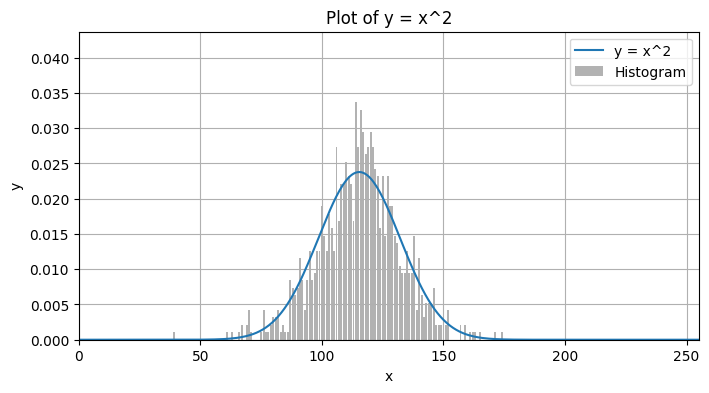

In [ ]:
#Gaussian noise curve estimation

grapha = zoomMean
graphb = math.sqrt(zoomVariance)

def gaussianGraph(z):
  partOne = 1 / (np.sqrt(2 * math.pi) * graphb)

  exponent = -1 * (np.power(z - grapha, 2)) / (2 * np.power(graphb, 2))

  return partOne * np.exp(exponent)

normalizedHistogramArray = []

max = -1
for i in range(256):
  normalizedHistogramArray.append(histogramArray[i] / size)
  if (normalizedHistogramArray[i] > max):
    max = normalizedHistogramArray[i]

# Define the range of x values
x = np.linspace(0, 256, 400)  # 400 points between -10 and 10

# Define the function
y = gaussianGraph(x)

plt.figure(figsize=(8,4))
plt.bar(range(256), normalizedHistogramArray, color='gray', alpha=0.6, label='Histogram')


# Plot the function
plt.plot(x, y, label='y = x^2')

# Add labels and title
plt.xlabel('x')
plt.xlim(0, 255)
plt.ylim(0, max + 0.01)
plt.ylabel('y')
plt.title('Plot of y = x^2')
plt.legend()
plt.grid(True)

# Show the plot
plt.show()

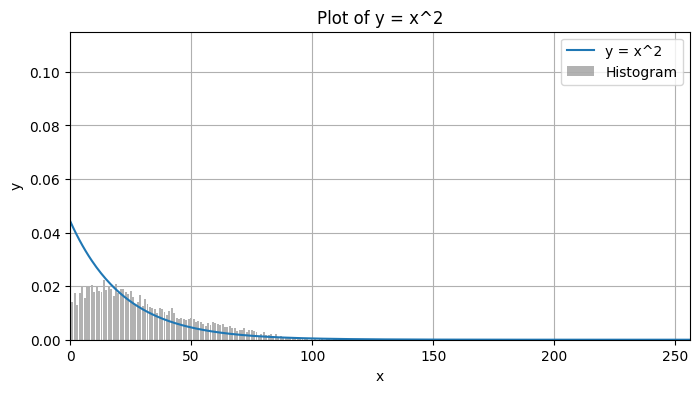

1.0228685873941712


In [ ]:
#Exponential noise curve estimation

grapha = 1 / np.sqrt(zoomVariance)
functionNormalizeFactor = 0
def exponentialGraph(z):
  return grapha * np.exp(-1 * grapha * z)

for i in range(256):
  functionNormalizeFactor += exponentialGraph(i)

def exponentialGraph(z):
  return grapha * np.exp(-1 * grapha * z) / functionNormalizeFactor

normalizedHistogramArray = []

max = -1
for i in range(256):
  normalizedHistogramArray.append(histogramArray[i] / size)
  if (normalizedHistogramArray[i] > max):
    max = normalizedHistogramArray[i]

# Define the range of x values
x = np.linspace(0, 256, 400)  # 400 points between -10 and 10

# Define the function
y = exponentialGraph(x)

plt.figure(figsize=(8,4))
plt.bar(range(256), normalizedHistogramArray, color='gray', alpha=0.6, label='Histogram')


# Plot the function
plt.plot(x, y, label='y = x^2')

# Add labels and title
plt.xlabel('x')
plt.xlim(0, 256)
plt.ylim(0, max + 0.01)
plt.ylabel('y')
plt.title('Plot of y = x^2')
plt.legend()
plt.grid(True)

# Show the plot
plt.show()

print(functionNormalizeFactor)

# **Mean Filters**

In [ ]:
blockWidth = 10
blockHeight = 10
blockSize = blockWidth * blockHeight

outImg = Image.new(mode="L", size=(width1, height1))

outPixels = outImg.load()
for i in range(width1):
  for j in range(height1):
    pixelVal = 0

    for k in range(i - math.floor(blockWidth / 2), i + math.ceil(blockWidth / 2)):
      for l in range(j - math.floor(blockHeight / 2), j + math.ceil(blockHeight / 2)):
        if ((k >= 0 and k < width1) and (l >= 0 and l < height1)):
          pixelVal += pixels1[k, l] / blockSize

    outPixels[i, j] = int(pixelVal)
  if (i % 100 == 0):
    print("finished row " + str(i))
outImg.save("filter.jpg")

finished row 0
finished row 100
finished row 200
finished row 300
finished row 400
finished row 500
finished row 600
finished row 700


In [ ]:
significance = [
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
]

significance = [
    [1, 2, 4, 8, 16, 16,  8, 4, 2, 1],
    [2, 4, 8, 16, 32, 32, 16,  8, 4, 2],
    [4, 8, 16, 32, 64, 64, 32, 16,  8, 4],
    [8, 16, 32, 64, 128, 128, 64, 32, 16, 8],
    [16, 32, 64, 128, 256, 256, 128, 64, 32, 16],
    [16, 32, 64, 128, 256, 256, 128, 64, 32, 16],
    [8, 16, 32, 64, 128, 128, 64, 32, 16, 8],
    [4, 8, 16, 32, 64, 64, 32, 16,  8, 4],
    [2, 4, 8, 16, 32, 32, 16,  8, 4, 2],
    [1, 2, 4, 8, 16, 16,  8, 4, 2, 1]
]

significance = [
    [1, 2, 4, 2, 1],
    [2, 4, 8, 4, 2],
    [4, 8, 16, 8, 4],
    [2, 4, 8, 4, 2],
    [1, 2, 4, 2, 1]
    ]

In [ ]:
blockWidth = 10
blockHeight = 10
blockSize = blockWidth * blockHeight

significance = [
    [1, 2, 4, 8, 16, 16,  8, 4, 2, 1],
    [2, 4, 8, 16, 32, 32, 16,  8, 4, 2],
    [4, 8, 16, 32, 64, 64, 32, 16,  8, 4],
    [8, 16, 32, 64, 128, 128, 64, 32, 16, 8],
    [16, 32, 64, 128, 256, 256, 128, 64, 32, 16],
    [16, 32, 64, 128, 256, 256, 128, 64, 32, 16],
    [8, 16, 32, 64, 128, 128, 64, 32, 16, 8],
    [4, 8, 16, 32, 64, 64, 32, 16,  8, 4],
    [2, 4, 8, 16, 32, 32, 16,  8, 4, 2],
    [1, 2, 4, 8, 16, 16,  8, 4, 2, 1]
]
significanceTotal = 0
for i in range(blockWidth):
  for j in range(blockHeight):
    significanceTotal += significance[i][j]


outImg = Image.new(mode="L", size=(width1, height1))

outPixels = outImg.load()
for i in range(width1):
  for j in range(height1):
    pixelVal = 0

    for k in range(i - math.floor(blockWidth / 2), i + math.ceil(blockWidth / 2)):
      for l in range(j - math.floor(blockHeight / 2), j + math.ceil(blockHeight / 2)):
        if ((k >= 0 and k < width1) and (l >= 0 and l < height1)):
          pixelVal += (pixels1[k, l] * significance[k - i + math.floor(blockWidth / 2)][l - j + math.floor(blockHeight / 2)]) / significanceTotal

    outPixels[i, j] = int(pixelVal)
  if (i % 100 == 0):
    print("finished row " + str(i))
outImg.save("filter.jpg")

finished row 0
finished row 100
finished row 200
finished row 300
finished row 400
finished row 500
finished row 600
finished row 700


In [ ]:
blockWidth = 10
blockHeight = 10

d = 40

blockSize = blockWidth * blockHeight

outImg = Image.new(mode="L", size=(width1, height1))

outPixels = outImg.load()
for i in range(width1):
  for j in range(height1):
    pixelVal = 0
    neighbors = []

    for k in range(i - math.floor(blockWidth / 2), i + math.ceil(blockWidth / 2)):
      for l in range(j - math.floor(blockHeight / 2), j + math.ceil(blockHeight / 2)):
        if ((k >= 0 and k < width1) and (l >= 0 and l < height1)):
          neighbors.append(pixels1[k, l])
        else:
          neighbors.append(0)

    neighbors.sort()

    newNeighbors = neighbors[d//2:-(d//2)]

    for num in newNeighbors:
      pixelVal += num

    pixelVal /= len(newNeighbors)

    outPixels[i, j] = int(pixelVal)
  if (i % 100 == 0):
    print("finished row " + str(i))
outImg.save("filter.jpg")

finished row 0
finished row 100
finished row 200
finished row 300
finished row 400
finished row 500
finished row 600
finished row 700


In [ ]:
blockWidth = 10
blockHeight = 10
blockSize = blockWidth * blockHeight

outImg = Image.new(mode="L", size=(width1, height1))

outPixels = outImg.load()
for i in range(width1):
  for j in range(height1):
    pixelVal = 1

    for k in range(i - math.floor(blockWidth / 2), i + math.ceil(blockWidth / 2)):
      for l in range(j - math.floor(blockHeight / 2), j + math.ceil(blockHeight / 2)):
        if ((k >= 0 and k < width1) and (l >= 0 and l < height1)):
          pixelVal *= pixels1[k, l]
        else:
          pixelVal *= 0
    outPixels[i, j] = int(math.pow(pixelVal, (1 / (blockWidth * blockHeight))))
  if (i % 100 == 0):
    print("finished row " + str(i))
outImg.save("filter.jpg")

finished row 0
finished row 100
finished row 200
finished row 300
finished row 400
finished row 500
finished row 600
finished row 700


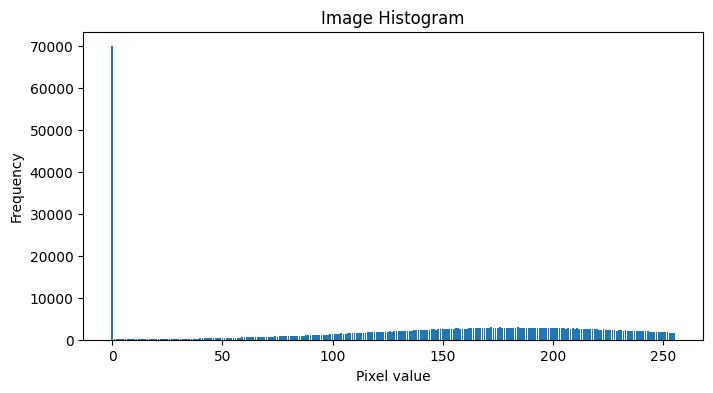

72


In [ ]:
# ---- get histogram ----
histogram = defaultdict(int)

for i in range(width1):
  for j in range(height1):
    histogram[noisePixels[i, j]] += 1

histogramArray = []

for i in range(256):
  histogramArray.append(histogram[i])
# ---- plot histogram as bars ----
plt.figure(figsize=(8,4))
plt.bar(range(256), histogramArray)
plt.title("Image Histogram")
plt.xlabel("Pixel value")
plt.ylabel("Frequency")
plt.show()
print(histogramArray[1])

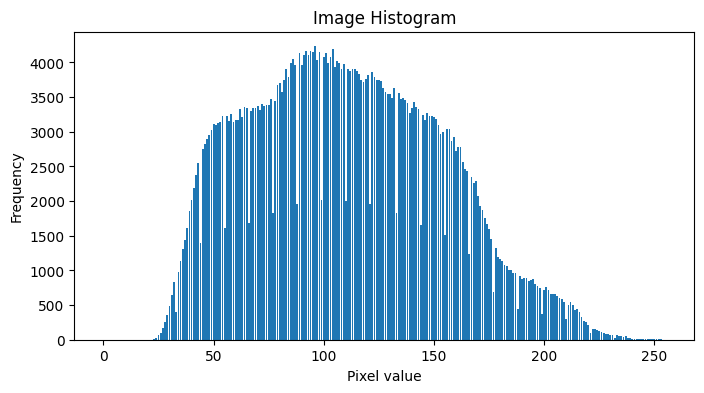

0


In [ ]:
# ---- get histogram ----
histogram = defaultdict(int)

outImgPixels = outImg.load()
for i in range(width1):
  for j in range(height1):
    histogram[outImgPixels[i, j]] += 1

histogramArray = []

for i in range(256):
  histogramArray.append(histogram[i])
# ---- plot histogram as bars ----
plt.figure(figsize=(8,4))
plt.bar(range(256), histogramArray)
plt.title("Image Histogram")
plt.xlabel("Pixel value")
plt.ylabel("Frequency")
plt.show()
print(histogramArray[1])

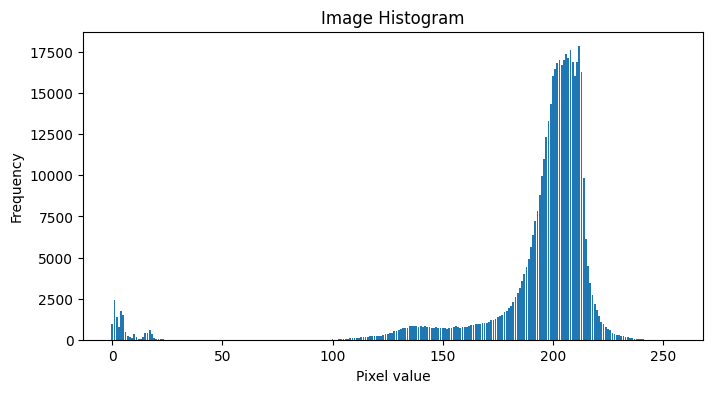

2387


In [ ]:
# ---- get histogram ----
histogram = defaultdict(int)

for i in range(width1):
  for j in range(height1):
    histogram[pixels1[i, j]] += 1

histogramArray = []

for i in range(256):
  histogramArray.append(histogram[i])
# ---- plot histogram as bars ----
plt.figure(figsize=(8,4))
plt.bar(range(256), histogramArray)
plt.title("Image Histogram")
plt.xlabel("Pixel value")
plt.ylabel("Frequency")
plt.show()
print(histogramArray[1])

# **Adaptive Noise Filter**

In [ ]:
#Zoom into segment of image
startx = 20
endx =  90
starty = 10
endy = 100

localWidthHeight = 5


def localStats(img_np, x, y, w):
  half = w // 2

  x1 = 0 if (x - half) < 0 else x - half
  x2 = min(len(img_np), x + half + 1)
  y1 = 0 if (y - half) < 0 else y - half
  y2 = min(len(img_np[0]), y + half + 1)

  window = img_np[x1:x2, y1:y2].astype(np.float64)

  mL = np.mean(window)
  varL = np.var(window)
  return mL, varL


zoomImg = Image.new(mode="L", size=(endx - startx, endy - starty))

zoomPixels = zoomImg.load()
for i in range(startx, endx):
  for j in range(starty, endy):
    pixelVal1 = pixels1[i, j]

    zoomPixels[i - startx, j - starty] = pixelVal1

zoomImg.save("zoom.jpg")

zoomMean = 0
zoomVariance = 0
size = (endx - startx) * (endy - starty)

for i in range(endx - startx):
  for j in range(endy - starty):
    pixelVal = zoomPixels[i,j]
    zoomMean += pixelVal
    zoomVariance += (pixelVal * pixelVal)

zoomMean /= size
zoomVariance = (zoomVariance / size) - (zoomMean * zoomMean)

print(str(zoomMean) + " " + str(zoomVariance))


tempImg = Image.open(input1).convert("L") # Save greyscaled version of input
img_np = np.array(tempImg) # Convert to numpy array for efficient calculation

outImg = Image.new(mode="L", size=(width1, height1))

outPixels = outImg.load()

for i in range(width1):
  for j in range(height1):
    locMean, locVar = localStats(img_np, j, i, localWidthHeight)

    if (i % 100 == 0 and j % 100 == 0):
      print("on row " + str(i))

    outPixels[i, j] = int(img_np[j, i] - ((zoomVariance / (1 if (min(zoomVariance, locVar) * (img_np[j, i] - locMean)) == 0 else (min(zoomVariance, locVar) * (img_np[j, i] - locMean))))))

outImg.save("output.jpg")

99.67793650793651 176.77357669438243
on row 0
on row 0
on row 0
on row 0
on row 0
on row 0
on row 100
on row 100
on row 100
on row 100
on row 100
on row 100
on row 200
on row 200
on row 200
on row 200
on row 200
on row 200
on row 300
on row 300
on row 300
on row 300
on row 300
on row 300
on row 400
on row 400
on row 400
on row 400
on row 400
on row 400
on row 500
on row 500
on row 500
on row 500
on row 500
on row 500
on row 600
on row 600
on row 600
on row 600
on row 600
on row 600
on row 700
on row 700
on row 700
on row 700
on row 700
on row 700


In [ ]:
#Zoom into segment of image
startx = width1 - 100
endx =  width1
starty = height1 - 100
endy = height1

localWidthHeight = 10


def localStats(img_np, x, y, w):
  half = w // 2

  x1 = 0 if (x - half) < 0 else x - half
  x2 = min(len(img_np), x + half + 1)
  y1 = 0 if (y - half) < 0 else y - half
  y2 = min(len(img_np[0]), y + half + 1)

  window = img_np[x1:x2, y1:y2].astype(np.float64)

  mL = np.mean(window)
  varL = np.var(window)
  return mL, varL


zoomImg = Image.new(mode="L", size=(endx - startx, endy - starty))

zoomPixels = zoomImg.load()
for i in range(startx, endx):
  for j in range(starty, endy):
    pixelVal1 = pixels1[i, j]

    zoomPixels[i - startx, j - starty] = pixelVal1

zoomImg.save("zoom.jpg")

zoomMean = 0
zoomVariance = 0
size = (endx - startx) * (endy - starty)

for i in range(endx - startx):
  for j in range(endy - starty):
    pixelVal = zoomPixels[i,j]
    zoomMean += pixelVal
    zoomVariance += (pixelVal * pixelVal)

zoomMean /= size
zoomVariance = (zoomVariance / size) - (zoomMean * zoomMean)

print(str(zoomMean) + " " + str(zoomVariance))


tempImg = Image.open(input1).convert("L") # Save greyscaled version of input
img_np = np.array(tempImg) # Convert to numpy array for efficient calculation

outImg = Image.new(mode="L", size=(width1, height1))

outPixels = outImg.load()

for i in range(width1):
  for j in range(height1):
    locMean, locVar = localStats(img_np, j, i, localWidthHeight)

    if (i % 100 == 0 and j % 100 == 0):
      print("on row " + str(i))

    if locVar == 0:
      outPixels[i, j] = int(locMean)
    else:
      outPixels[i, j] = int(
        locMean + (max(locVar - zoomVariance, 0) / locVar) * (img_np[j, i] - locMean)
    )

outImg.save("output.jpg")

75.6294 2233.057655639999
on row 0
on row 0
on row 0
on row 0
on row 0
on row 0
on row 100
on row 100
on row 100
on row 100
on row 100
on row 100
on row 200
on row 200
on row 200
on row 200
on row 200
on row 200
on row 300
on row 300
on row 300
on row 300
on row 300
on row 300
on row 400
on row 400
on row 400
on row 400
on row 400
on row 400
on row 500
on row 500
on row 500
on row 500
on row 500
on row 500
on row 600
on row 600
on row 600
on row 600
on row 600
on row 600
on row 700
on row 700
on row 700
on row 700
on row 700
on row 700


# **Image Sharpening**

In [ ]:
#Logarithmic Subtraction (assuming greyscaled)

M = 255

filterImg = Image.open("filter.jpg")

filterPixels = filterImg.load()

detailImg = Image.new(mode="L", size=(width1, height1))
detailPixels = detailImg.load()

for i in range(width1):
  for j in range(height1):
    filterPixels[i, j] = 255 - filterPixels[i, j]
    pixels1[i, j] = 255 - pixels1[i, j]

for i in range(width1):
  for j in range(height1):
    pixelVal1 = pixels1[i, j]
    pixelVal2 = filterPixels[i, j]

    newPixelVal = int(M * ((pixelVal1 - pixelVal2) / ((M + 1) - pixelVal2)))

    detailPixels[i, j] = newPixelVal

for i in range(width1):
  for j in range(height1):
    filterPixels[i, j] = 255 - filterPixels[i, j]
    pixels1[i, j] = 255 - pixels1[i, j]
    detailPixels[i, j] = 255 - detailPixels[i, j]

detailImg.save("detail.jpg")

In [ ]:
# Get detailed picture

filterImg = Image.open("filter.jpg")

filterPixels = filterImg.load()

detailImg = Image.new(mode="L", size=(width1, height1))
detailPixels = detailImg.load()

for i in range(width1):
  for j in range(height1):
    pixelVal = pixels1[i, j] - filterPixels[i, j]

    detailPixels[i, j] = int(pixelVal)

detailImg.save("detail.jpg")

In [ ]:
#Add detail back (logarithm)

alpha67 = 1

M = 255 * (255 * alpha67)

outImg = Image.new(mode="L", size=(width1, height1))

outPixels = outImg.load()

detailImg = Image.open("detail.jpg")
detailPixels = detailImg.load()

for i in range(width1):
  for j in range(height1):
    detailPixels[i, j] = 255 - detailPixels[i, j]
    pixels1[i, j] = 255 - pixels1[i, j]

for i in range(width1):
  for j in range(height1):
    pixelVal1 = pixels1[i, j]
    pixelVal2 = detailPixels[i, j] * alpha67

    newPixelVal = int(pixelVal1 + pixelVal2 - ((pixelVal1 * pixelVal2) / M))

    print(newPixelVal)

    outPixels[i, j] = newPixelVal

for i in range(width1):
  for j in range(height1):
    detailPixels[i, j] = 255 - detailPixels[i, j]
    pixels1[i, j] = 255 - pixels1[i, j]
    outPixels[i, j] = 255 - outPixels[i, j]
outImg.save("output.jpg")

Streaming output truncated to the last 5000 lines.
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
271
271
271
271
271
271
271
271
259
259
259
259
259
259
259
259
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
268
273
273
273
273
273
273
273
273
261
261
261
261
261
261
261
261
268
268
268
268
268
268
268
268
257
257
257
257
257
257
257
257
268
268
268
268
268
268
268
268
271
271
271
271
271
271
271
271
264
266
237
261
305
241
238
389
253
235
238
246
233
232
235
234
233
233
233
233
233
233
233
233
233
233
233
233
233
233
233
233
233
233
233
233
233
233
233
233
233
233
233
233
233
2

In [ ]:
alpha67 = 1

detailImg = Image.open("detail.jpg")
detailPixels = detailImg.load()

outImg = Image.new(mode="L", size=(width1, height1))
outPixels = outImg.load()

for i in range(width1):
  for j in range(height1):
    pixelVal1 = pixels1[i, j]
    pixelVal2 = detailPixels[i, j] * alpha67

    newPixelVal = pixelVal1 + pixelVal2

    outPixels[i, j] = newPixelVal

outImg.save("output.jpg")